# 08 Decomposition: how big is the data center slice?
We split the change in the all-in wholesale price (energy + capacity, real 2025 $/MWh) between the
**2019–21 average** and the **latest 12 months (Aug 2025 – Jul 2026)** into its causes:

| Slice | How we measure it |
|---|---|
| Gas, weather, renewables, carbon (RGGI) | coefficient from the DiD model (05) × change in that variable |
| **Data centers – local** | extra price where data centers are (DiD, Double ML, synthetic control) |
| **Data centers – PJM-wide, capacity** | Market Monitor (IMM): share of capacity cost caused by data center load |
| **Data centers – PJM-wide, energy** | PJM West vs other US hubs after 2023 (05, track 2), read as an upper bound |
| Other PJM-wide factors | what is left: capacity rule changes, plant retirements, anything not explained |

The answer is a **range**: low / central / high, built from the different methods (not one exact number).

Section 2.2.5 and Tables 2.6–2.7 of the thesis.

In [1]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from utils import CLEAN, save_fig

zone = pd.read_parquet(CLEAN / "panel_zone_month.parquet")
CONTROLS = ["gas_real", "hdd", "cdd", "renew_share", "rggi_real"]
BASE, LATEST = ("2019-01-01", "2021-12-01"), ("2025-08-01", "2026-07-01")

def change(df, col):
    a = df[(df.month >= BASE[0]) & (df.month <= BASE[1])][col].mean()
    b = df[(df.month >= LATEST[0]) & (df.month <= LATEST[1])][col].mean()
    return b - a

## 1. Ingredients
### 1a. Control coefficients
Same model as notebook 05, Track 1.

In [2]:
m = smf.ols(f"wholesale_real ~ dc_share + {' + '.join(CONTROLS)} + C(zone) + C(month)", zone).fit(
    cov_type="cluster", cov_kwds={"groups": zone.zone.astype("category").cat.codes})
beta = m.params[CONTROLS]
beta.round(2)

gas_real        1.48
hdd            -0.00
cdd             0.05
renew_share   -40.34
rggi_real       0.12
dtype: float64

### 1b. Local data center effect for Dominion
The five point estimates of notebooks 05, 06 and 07 (Table 2.5).

In [3]:
did = pd.read_csv(CLEAN / "did_track1.csv")
dml_res = pd.read_csv(CLEAN / "dml_results.csv")
sc = pd.read_csv(CLEAN / "synthetic_summary.csv")
local = pd.Series({
    "DiD (our DC list)": did.query("outcome == 'wholesale_real' and exposure == 'dc_share'").dom_usd_mwh.item(),
    "DiD (PJM large-load data)": did.query("outcome == 'wholesale_real' and exposure == 'll_share'").dom_usd_mwh.item(),
    "Double ML (random forest)": dml_res.query("outcome == 'wholesale_real' and learner == 'Random forest'").theta_dom.item(),
    "Double ML (gradient boosting)": dml_res.query("outcome == 'wholesale_real' and learner == 'Gradient boosting'").theta_dom.item(),
    "Synthetic control": sc.gap_latest12m.item()})
local.round(1)

DiD (our DC list)                26.9
DiD (PJM large-load data)        22.7
Double ML (random forest)        30.6
Double ML (gradient boosting)    26.7
Synthetic control                34.1
dtype: float64

### 1c. PJM-wide data center effect
* **Capacity.** Market Monitor (IMM): data center load raised capacity costs by $9.3bn of $14.7bn in 2025/26 (63%), $7.3bn of $16.1bn in 2026/27 (45%) and $6.5bn of $16.4bn in 2027/28 (40%). The latest 12 months are 10 months of 2025/26 and 2 of 2026/27, so the central share is 60%. It is applied to the capacity price change in the rest of PJM.
* **Energy.** Track 2 (δ ≈ +11.5 $/MWh) is an upper bound: low = none of it, central = half, high = all of it.

In [4]:
imm_share = {"low": 6.5 / 16.4, "central": (10 * 9.3 / 14.7 + 2 * 7.3 / 16.1) / 12, "high": 9.3 / 14.7}
t2 = pd.read_csv(CLEAN / "did_track2.csv").iloc[0]
energy_sys = {"low": 0.0, "central": t2.beta / 2, "high": t2.beta}

rest = zone[~zone.zone.isin(["DOM", "BGE", "PEPCO", "APS"])]          # zones with little local exposure
pjm_capacity_change = change(rest, "capacity_mwh_real")
print({k: round(v, 2) for k, v in imm_share.items()}, "| PJM-wide capacity change:", round(pjm_capacity_change, 1))
print("Real gas price change, DOM:", round(change(zone[zone.zone == "DOM"], "gas_real"), 2), "$/Mcf")

{'low': 0.4, 'central': 0.6, 'high': 0.63} | PJM-wide capacity change: 7.6
Real gas price change, DOM: -0.08 $/Mcf


## 2. Decomposition for Dominion and for the rest of PJM
Controls = coefficient × change in the control. The last slice ("other PJM-wide factors") is what remains, so the slices always add up to the total change. The rest of PJM excludes Dominion and its neighbours BGE, Pepco and APS.

In [5]:
def decompose(df, local_dc):
    total = change(df, "wholesale_real")
    rows = {"Gas": beta.gas_real * change(df, "gas_real"),
            "Weather": beta.hdd * change(df, "hdd") + beta.cdd * change(df, "cdd"),
            "Renewables": beta.renew_share * change(df, "renew_share"),
            "Carbon (RGGI)": beta.rggi_real * change(df, "rggi_real")}
    out = {}
    for case in ["low", "central", "high"]:
        r = dict(rows)
        r["Data centers – local"] = local_dc[case]
        r["Data centers – PJM capacity"] = imm_share[case] * pjm_capacity_change
        r["Data centers – PJM energy"] = energy_sys[case]
        r["Other PJM-wide factors"] = total - sum(r.values())
        out[case] = r
    res = pd.DataFrame(out)
    res.loc["Total change"] = total
    dc_rows = [i for i in res.index if i.startswith("Data centers")]
    res.loc["Data centers – total"] = res.loc[dc_rows].sum()
    res.loc["Data center share of the increase (%)"] = res.loc["Data centers – total"] / total * 100
    return res

dom_local = {"low": local.min(), "central": local.median(), "high": local.max()}
rest_local = {c: v * change(rest, "dc_share") / change(zone[zone.zone == "DOM"], "dc_share") for c, v in dom_local.items()}

dom_table = decompose(zone[zone.zone == "DOM"], dom_local)
rest_table = decompose(rest, rest_local)
dom_table.round(1)

,low,central,high
Gas,-0.1,-0.1,-0.1
Weather,-0.7,-0.7,-0.7
Renewables,-3.1,-3.1,-3.1
Carbon (RGGI),-0.1,-0.1,-0.1
Data centers – local,22.7,26.9,34.1
Data centers – PJM capacity,3.0,4.6,4.8
Data centers – PJM energy,0.0,5.8,11.5
Other PJM-wide factors,37.7,26.2,13.0
Total change,59.5,59.5,59.5
Data centers – total,25.7,37.3,50.4


In [6]:
rest_table.round(1)

,low,central,high
Gas,1.3,1.3,1.3
Weather,-0.6,-0.6,-0.6
Renewables,-1.2,-1.2,-1.2
Carbon (RGGI),0.7,0.7,0.7
Data centers – local,0.0,0.0,0.0
Data centers – PJM capacity,3.0,4.6,4.8
Data centers – PJM energy,0.0,5.8,11.5
Other PJM-wide factors,22.3,14.9,8.9
Total change,25.5,25.5,25.5
Data centers – total,3.0,10.4,16.4


## 3. Waterfall chart (Dominion, central case, Figure 2.7)

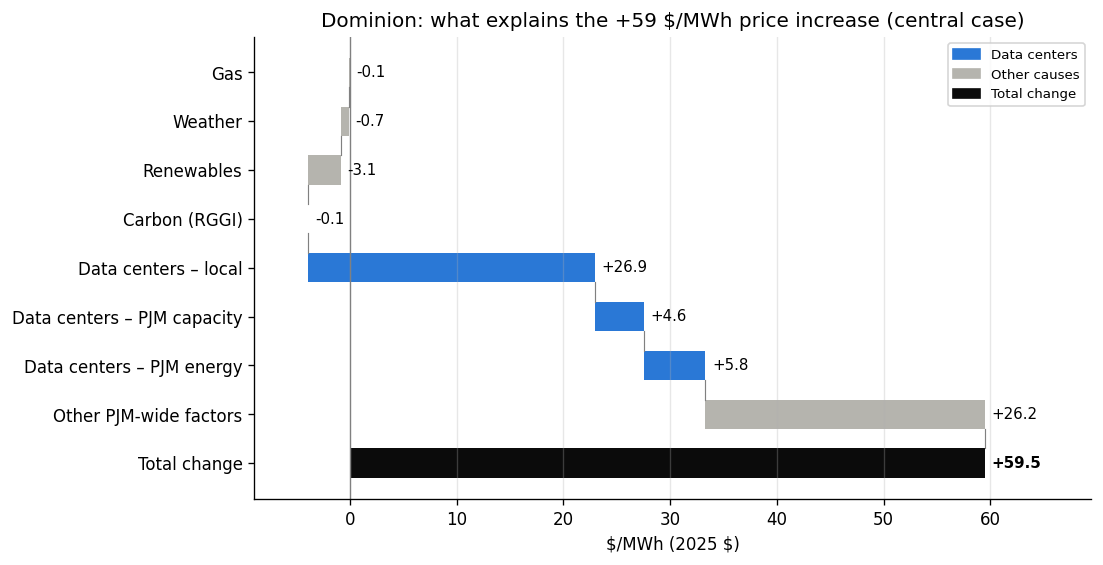

In [7]:
w = dom_table["central"].drop(["Total change", "Data centers – total", "Data center share of the increase (%)"])
labels = list(w.index) + ["Total change"]
starts = np.concatenate([[0], np.cumsum(w.values)[:-1]])
y = np.arange(len(labels))[::-1]                                  # first slice at the top

fig, ax = plt.subplots(figsize=(9, 5))
for i, (name, v, s0) in enumerate(zip(w.index, w.values, starts)):
    ax.barh(y[i], v, left=s0, height=0.6, color="#2a78d6" if name.startswith("Data centers") else "#b5b4ae")
    end = s0 + v
    ax.annotate(f"{v:+.1f}", (max(s0, end), y[i]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.plot([end, end], [y[i] - 0.3, y[i] - 0.7], color="grey", lw=0.7)        # connector to the next bar
total = w.sum()
ax.barh(y[-1], total, height=0.6, color="#0b0b0b")
ax.annotate(f"{total:+.1f}", (total, y[-1]), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, weight="bold")
ax.axvline(0, color="grey", lw=0.8)
ax.set_yticks(y, labels)
ax.set_xlim(min(starts.min(), 0) - 5, total + 10)
ax.grid(axis="y", visible=False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in ["#2a78d6", "#b5b4ae", "#0b0b0b"]],
          labels=["Data centers", "Other causes", "Total change"], loc="upper right", fontsize=8)
ax.set(title="Dominion: what explains the +59 $/MWh price increase (central case)", xlabel="$/MWh (2025 $)")
save_fig("08_waterfall_dom")

## 4. Final answer
Share of the price increase attributed to data centers: Dominion 43% / 63% / 85%, rest of PJM 12% / 41% / 64% (Table ES.1).

In [8]:
summary = pd.DataFrame({
    "Dominion (VA)": dom_table.loc["Data center share of the increase (%)"],
    "Rest of PJM": rest_table.loc["Data center share of the increase (%)"]}).T
summary.columns = ["Low (%)", "Central (%)", "High (%)"]
dom_table.to_csv(CLEAN / "decomposition_dom.csv")
rest_table.to_csv(CLEAN / "decomposition_rest.csv")
summary.to_csv(CLEAN / "final_answer.csv")
summary.round(0)

,Low (%),Central (%),High (%)
Dominion (VA),43.0,63.0,85.0
Rest of PJM,12.0,41.0,64.0
